# 3D-ΔPDF by Fourier transform: a synthetic example

**This is a synthetic volume, not DISCUS output.** A quantitative 3D-ΔPDF requires a Bragg-subtracted diffuse intensity volume on a corrected, centered Cartesian Q grid; Bragg subtraction, masking, normalization, and voxel interpolation are outside this starter.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from discuspdf import delta_pdf_from_diffuse, plot_delta_pdf_slice, FFTValidationError

## 1. Construct a synthetic centrosymmetric diffuse intensity

Coordinates below are in physical Q units Å⁻¹.

In [2]:
n = 64
dq = 0.15  # Å^-1
q = (np.arange(n) - n//2) * dq
qx, qy, qz = np.meshgrid(q, q, q, indexing="ij")
# An example smooth, nonnegative centrosymmetric feature
i_diff = np.exp(-((qx-1.1)**2+qy**2+qz**2)/(2*0.35**2))
i_diff += np.exp(-((qx+1.1)**2+qy**2+qz**2)/(2*0.35**2))

## 2. Transform to a real-space 3D-ΔPDF

FFTDiagnostics(imaginary_ratio=1.1410716794337586e-16, max_imaginary=3.597099718310513e-19, max_real=0.005444579281361164, friedel_relative_error=0.0, dq=(0.15, 0.15, 0.15), reciprocal_voxel_volume=0.003375, normalization='dQx*dQy*dQz/(2*pi)^3; exp(-i Q.r)')


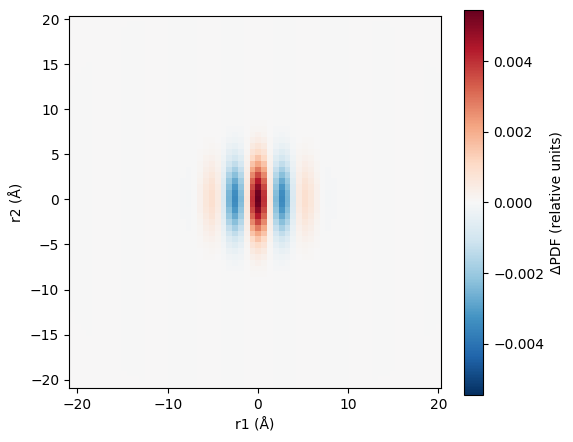

In [3]:
# delta_pdf_from_diffuse — FFT of a Bragg-subtracted 3D diffuse volume to real space (3D-ΔPDF)
#   diffuse_intensity    finite 3D array (or a ReciprocalVolume, then omit q_axes)
#   q_axes               three 1D Q axes in Å⁻¹, uniform, centered: q[i] = (i - n//2)·dq, lengths = array shape
#   imaginary_tolerance  max allowed imaginary/real norm ratio, >= 0 (default 1e-4)
#   raise_on_imaginary   True (default): ratio above tolerance raises FFTValidationError (exc.result holds
#                        the computed FFTResult); False: RuntimeWarning instead
#   normalization        exp(-i Q·r), scaled by dQx·dQy·dQz/(2π)³
#   returns              FFTResult: .complex_volume, .real_volume, .r_axes (Å, 2π·fftfreq),
#                        .diagnostics (imaginary_ratio, friedel_relative_error, dq, ...)
fft = delta_pdf_from_diffuse(i_diff, (q, q, q))
print(fft.diagnostics)
delta, r_axes = fft.real_volume, fft.r_axes
# plot_delta_pdf_slice — image of one 2D slice through a 3D ΔPDF volume
#   volume, r_axes   3D array and its three r axes (Å)
#   axis             axis normal to the slice: 0, 1 or 2 (default 2)
#   index            slice index along that axis (default: centre, shape[axis] // 2)
#   returns          the Axes (symmetric RdBu_r colour scale with colourbar)
ax = plot_delta_pdf_slice(delta, r_axes, axis=2)
plt.show()

## 3. Replace synthetic data with your own

For an HDF5 file, identify the actual dataset paths first. **Do not assume** a universal DISCUS HDF5 layout.

```python
from discuspdf import read_hdf5_volume, delta_pdf_from_diffuse, FFTValidationError
intensity, q_axes = read_hdf5_volume(
    "your_diffuse_volume.h5",
    intensity_dataset="/actual/intensity/path",
    q_datasets=("/actual/qx/path", "/actual/qy/path", "/actual/qz/path"),
)
try:
    fft = delta_pdf_from_diffuse(intensity, q_axes)
except FFTValidationError as exc:
    print(exc.result.diagnostics)  # the computed FFT is preserved on the exception
else:
    delta, r_axes = fft.real_volume, fft.r_axes
```

If the source uses h,k,l reciprocal-lattice coordinates, first map the data to an appropriately sampled Cartesian Q grid using the reciprocal-cell metric. This notebook never runs a real DISCUS 3D computation; see `docs/3D_INTEGRATION.md` for the runner workflow.